# MedPredict: Predicting Stroke 2026-27 | Kaggle Competitie
## Portfolio-opdracht 1: Voorspel herseninfarct

---
**Teamnaam:** **Y&T**  
**Competitie:** [Predicting stroke 2026-27 | Kaggle](https://www.kaggle.com/competitions/predicting-stroke-2026-27)  
**Datum:** 2026-09-10  
**Opleiding:** Applied Data Science & Artificial Intelligence  

### Teamleden & Kaggle Accounts
| # | Naam | Studentnummer | Kaggle Gebruikersnaam |
|---|------|---------------|----------------------|
| 1 | Tijn Duivenvoorden | 25059629 | [kaggle](https://www.kaggle.com/tijnd07) |
| 2 | Yorrick de Vries | 25066919 | [kaggle](https://www.kaggle.com/yorrickdevries) |



## Inhoudsopgave

1. [Exploratieve Data Analyse (EDA) & Data Voorbewerking](#1-exploratieve-data-analyse-eda--data-voorbewerking)
   - [Kolom Beschrijvingen](#11-kolom-beschrijvingen)
   - [Geschiktheid van de data voor Scikit-learn](#12-geschiktheid-van-de-data-voor-scikit-learn)
   - [Missende waardes](#13-missende-waardes)
   - [Basisstatistieken](#14-basisstatistieken)
   - [Verdelingen Numerieke Kolommen](#15-verdelingen-numerieke-kolommen)
   - [Verdeling Target Kolom (Stroke)](#16-verdeling-target-kolom-stroke)
   - [Correlaties met Target Kolom](#17-correlaties-met-target-kolom)
   - [Boxplots (Outliers)](#18-boxplots-outliers)
   - [Belangrijkste Bevindingen](#19-belangrijkste-bevindingen)
   - [Niet relevante kolommen](#110-niet-relevante-kolommen)
   - [Standaardisatie van de data](#111-standaardisatie-van-de-data)
2. [Evaluatie](#2-evaluatie)
3. [Modelleren en uitleg modellen](#3-modelleren-en-uitleg-modellen)
4. [Conclusie en advies](#4-conclusie-en-advies)
5. [Referentielijst en verantwoording generatieve AI](#5-referentielijst-en-verantwoording-generatieve-ai)

# 1. Exploratieve Data Analyse (EDA) & Data Voorbewerking

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns

In [19]:
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv') 

In [20]:
pd.set_option('display.max_columns', None)
train.head()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,stroke
0,52709,30.0,0,0,63.60,33.3,False,True,False,True,False,False,False,True,False,False,True,False,False,False,True,0
1,72295,75.0,1,0,215.17,48.0,True,False,False,False,True,False,False,False,True,False,True,False,False,True,False,0
2,26451,15.0,0,0,135.22,19.0,False,True,False,True,False,False,False,True,False,False,True,False,False,True,False,0
3,65210,47.0,0,0,64.89,28.2,False,True,False,False,True,False,False,False,True,False,False,True,False,True,False,0
4,69299,49.0,0,0,222.34,28.8,False,True,False,False,True,False,False,False,True,False,True,False,True,False,False,0


## 1.1 Kolom Beschrijvingen

**id**: Unique identifier for each individual patient record in the dataset.<br>
Geen medische betekenis. Dit is een administratief identificatienummer zonder voorspellende waarde.

**age**: Age of the patient in years (continuous numeric variable). <br>

**hypertension**: Binary flag, 1 if the patient has diagnosed chronic hypertension, 0 otherwise. <br>

**heart_disease**: Binary flag: 1 if the patient has a diagnosed heart disease, 0 otherwise. <br>

**avg_glucose_level**: Average blood glucose level measured in milligrams per deciliter (mg/dL).

**bmi**: Body Mass Index calculated as weight in kilograms divided by height in meters squared (kg/m²).

**gender_Female**: One-hot encoded columns indicating the biological gender of the patient.

**ever_married_No / ever_married_Yes**: One-hot encoded flag indicating whether the patient has ever been married.

**work_type_Private / Self_employed / Govt_job / children / Never_worked**: One-hot encoded categories representing the patient's employment sector or status.

**Residence_type_Urban / Residence_type_Rural**: One-hot encoded column indicating urban (stad) versus rural (platteland) residence.

**smoking_status_smokes / formerly_smoked / never_smoked**: One-hot encoded indicators of patient smoking history.

**stroke**: Target label: 1 if the patient experienced a stroke, 0 otherwise.

In [21]:
# Basisinformatie
print("Vorm van de dataset:")
print(train.shape)

print("\nKolommen:")
print(train.columns)

print("\nDatatypes:")
display(train.dtypes)

Vorm van de dataset:
(33550, 22)

Kolommen:
Index(['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level',
       'bmi', 'gender_Female', 'gender_Male', 'gender_Other',
       'ever_married_No', 'ever_married_Yes', 'work_type_Govt_job',
       'work_type_Never_worked', 'work_type_Private',
       'work_type_Self-employed', 'work_type_children', 'Residence_type_Rural',
       'Residence_type_Urban', 'smoking_status_formerly smoked',
       'smoking_status_never smoked', 'smoking_status_smokes', 'stroke'],
      dtype='object')

Datatypes:


id                                  int64
age                               float64
hypertension                        int64
heart_disease                       int64
avg_glucose_level                 float64
bmi                               float64
gender_Female                        bool
gender_Male                          bool
gender_Other                         bool
ever_married_No                      bool
ever_married_Yes                     bool
work_type_Govt_job                   bool
work_type_Never_worked               bool
work_type_Private                    bool
work_type_Self-employed              bool
work_type_children                   bool
Residence_type_Rural                 bool
Residence_type_Urban                 bool
smoking_status_formerly smoked       bool
smoking_status_never smoked          bool
smoking_status_smokes                bool
stroke                              int64
dtype: object

## 1.2 Geschiktheid van de data voor Scikit-learn

Minimale vereisten:
- Geen ontbrekende waarden.
- Alle features zijn numeriek (geen tekst of string). Categorische variabelen worden daarbij een getal gemaakt
- Geen oneindige of onmogelijke waarden
- X (features) en y (target) hebben evenveel rijen en de juiste vorm
- Geen irrelevante of identificerende features (zoals id) in de dataset

## 1.3 Missende waardes

In [22]:
# Missende waarden
missende_waarden = train.isnull().sum()

missende_waarden = pd.DataFrame({
    'Kolom': missende_waarden.index,
    'Aantal missend': missende_waarden.values
})

missende_waarden['Percentage missend'] = (
    missende_waarden['Aantal missend'] / len(train) * 100
)

display(missende_waarden)


,Kolom,Aantal missend,Percentage missend
0,id,0,0.0
1,age,0,0.0
2,hypertension,0,0.0
3,heart_disease,0,0.0
4,avg_glucose_level,0,0.0
5,bmi,0,0.0
6,gender_Female,0,0.0
7,gender_Male,0,0.0
8,gender_Other,0,0.0
9,ever_married_No,0,0.0


Wij zien dat we 0 missende waarden hebben.

## 1.4 Basisstatistieken

### 1.4.1 Numerieke kolommen

In [23]:
numerieke_kolommen = [
    'age',
    'avg_glucose_level',
    'bmi'
]

statistieken = []

for kol in numerieke_kolommen:
    statistieken.append({
        'Variabele': kol,
        'Gemiddelde': train[kol].mean(),
        'Mediaan': train[kol].median(),
        'Modus': train[kol].mode()[0],
        'Minimum': train[kol].min(),
        'Maximum': train[kol].max(),
        'Standaarddeviatie': train[kol].std(),
        'Variantie': train[kol].var(),
        'Bereik': train[kol].max() - train[kol].min()
    })

stats_train = pd.DataFrame(statistieken)

display(stats_train)

,Variabele,Gemiddelde,Mediaan,Modus,Minimum,Maximum,Standaarddeviatie,Variantie,Bereik
0,age,41.815312,43.00,50.00,0.08,82.00,22.477423,505.234542,81.92
1,avg_glucose_level,103.587081,91.32,77.47,55.01,281.59,42.127396,1774.717520,226.58
2,bmi,28.601216,27.70,27.60,10.10,97.60,7.782248,60.563389,87.50


### 1.4.2 Binaire Kolommen

In [24]:
binaire_kolommen = [
    'hypertension',
    'heart_disease',
    'stroke'
]

for kol in binaire_kolommen:
    print(f"\nVerdeling van {kol}:")
    
    verdeling = train[kol].value_counts().reset_index()
    verdeling.columns = [kol, 'Aantal']
    
    verdeling['Percentage'] = (
        verdeling['Aantal'] / len(train) * 100
    )
    
    display(verdeling)


Verdeling van hypertension:


,hypertension,Aantal,Percentage
0,0,30593,91.186289
1,1,2957,8.813711



Verdeling van heart_disease:


,heart_disease,Aantal,Percentage
0,0,32106,95.695976
1,1,1444,4.304024



Verdeling van stroke:


,stroke,Aantal,Percentage
0,0,33033,98.459016
1,1,517,1.540984


### 1.4.3 Categorische Kolommen

In [25]:
categorische_kolommen = train.select_dtypes(include='bool').columns

categorie_verdeling = []

for kol in categorische_kolommen:
    categorie_verdeling.append({
        'Categorie': kol,
        'Aantal True': train[kol].sum(),
        'Percentage': train[kol].mean() * 100
    })

categorie_stats = pd.DataFrame(categorie_verdeling)

display(categorie_stats)

,Categorie,Aantal True,Percentage
0,gender_Female,20032,59.707899
1,gender_Male,13512,40.274218
2,gender_Other,6,0.017884
3,ever_married_No,12124,36.137109
4,ever_married_Yes,21426,63.862891
5,work_type_Govt_job,4156,12.387481
6,work_type_Never_worked,141,0.420268
7,work_type_Private,19279,57.463487
8,work_type_Self-employed,5126,15.278689
9,work_type_children,4848,14.450075


## 1.5 Verdelingen Numerieke Kolommen

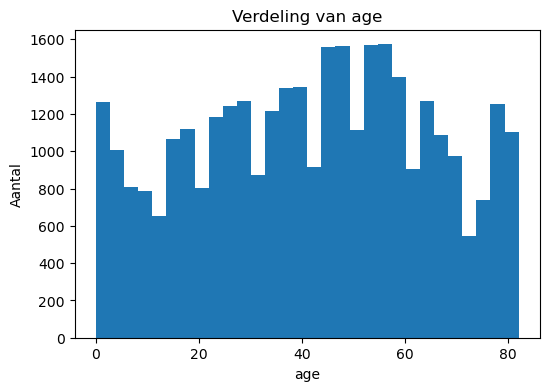

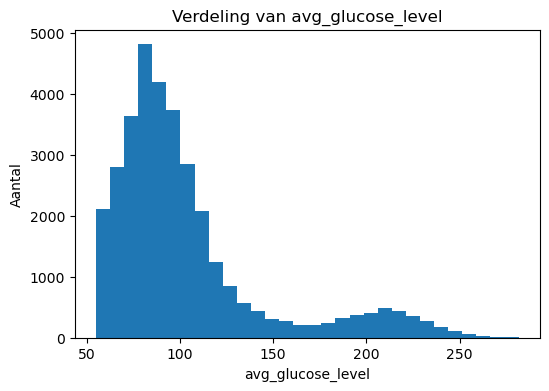

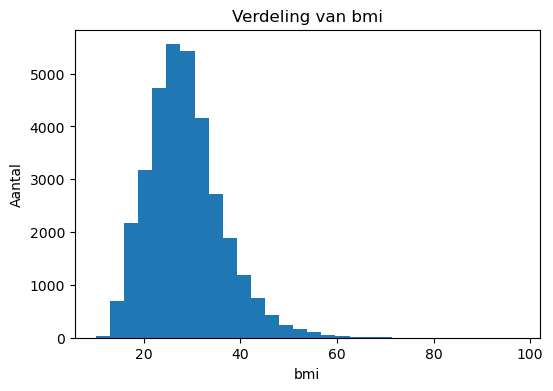

In [10]:
for kol in numerieke_kolommen:
    plt.figure(figsize=(6, 4))
    plt.hist(train[kol].dropna(), bins=30)
    plt.title(f'Verdeling van {kol}')
    plt.xlabel(kol)
    plt.ylabel('Aantal')
    plt.show()

## 1.6 Verdeling Target Kolom (Stroke)

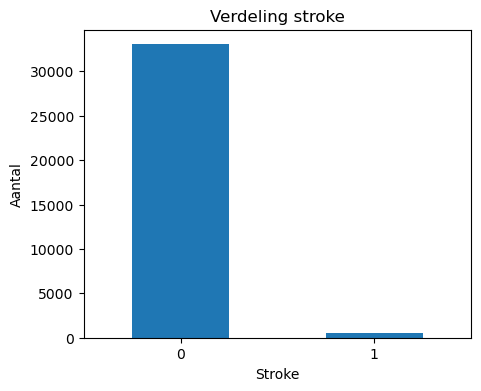

stroke
0    98.459016
1     1.540984
Name: proportion, dtype: float64


In [11]:
stroke_verdeling = train['stroke'].value_counts()

plt.figure(figsize=(5, 4))
stroke_verdeling.plot(kind='bar')

plt.title('Verdeling stroke')
plt.xlabel('Stroke')
plt.ylabel('Aantal')
plt.xticks(rotation=0)

plt.show()

print(train['stroke'].value_counts(normalize=True) * 100)

## 1.7 Correlaties met Target Kolom

In [12]:
correlaties = train.corr()['stroke'].drop('stroke')

correlaties = correlaties.reindex(
    correlaties.abs().sort_values(ascending=False).index
)

display(correlaties)

age                               0.148722
heart_disease                     0.104625
hypertension                      0.084019
avg_glucose_level                 0.076813
ever_married_Yes                  0.066403
ever_married_No                  -0.066403
work_type_Self-employed           0.061883
work_type_children               -0.050728
smoking_status_formerly smoked    0.034092
bmi                               0.020574
smoking_status_never smoked       0.009896
gender_Male                       0.008774
gender_Female                    -0.008727
smoking_status_smokes             0.008489
work_type_Never_worked           -0.008127
work_type_Private                -0.004937
work_type_Govt_job               -0.004439
Residence_type_Urban              0.002654
Residence_type_Rural             -0.002654
gender_Other                     -0.001673
id                                0.000691
Name: stroke, dtype: float64

### 1.7.1 Visualisatie

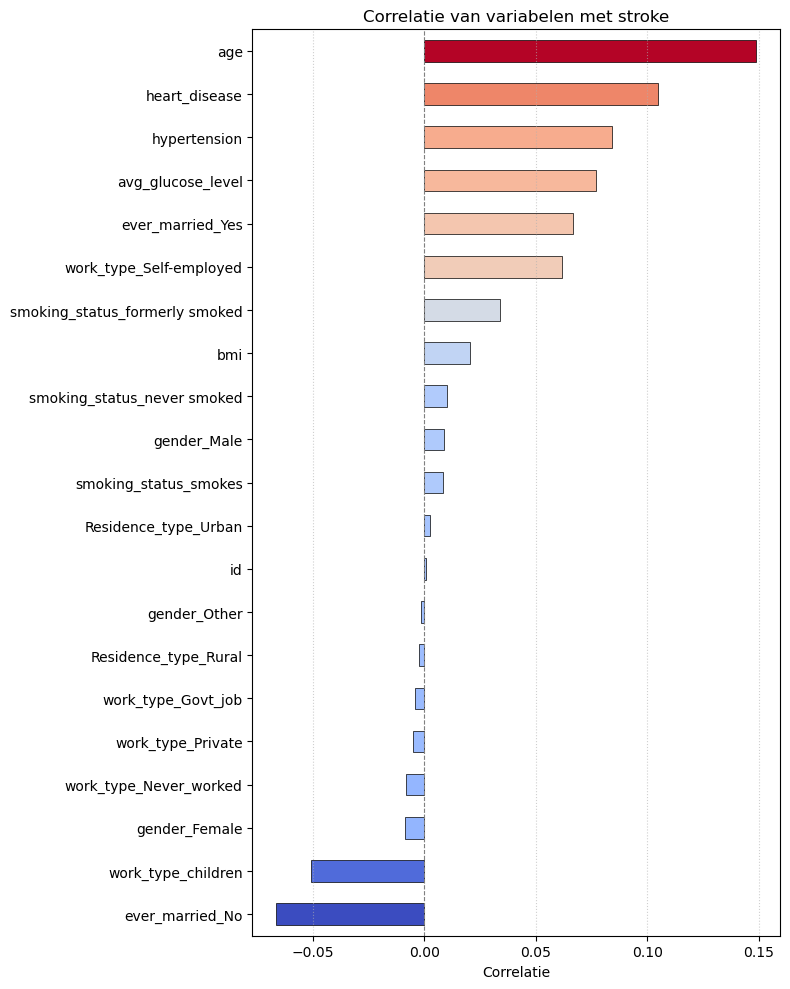

In [13]:
plt.figure(figsize=(8, 10))

data = correlaties.sort_values()

# Schaalt de waarden naar een colormap (bijv. van -1 naar 1 of min/max van de data)
norm = mcolors.Normalize(vmin=data.min(), vmax=data.max())
cmap = cm.coolwarm
kleuren = cmap(norm(data.values))

data.plot(kind='barh', color=kleuren, edgecolor='black', linewidth=0.5)

plt.axvline(0, color='grey', linewidth=0.8, linestyle='--')
plt.title('Correlatie van variabelen met stroke')
plt.xlabel('Correlatie')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

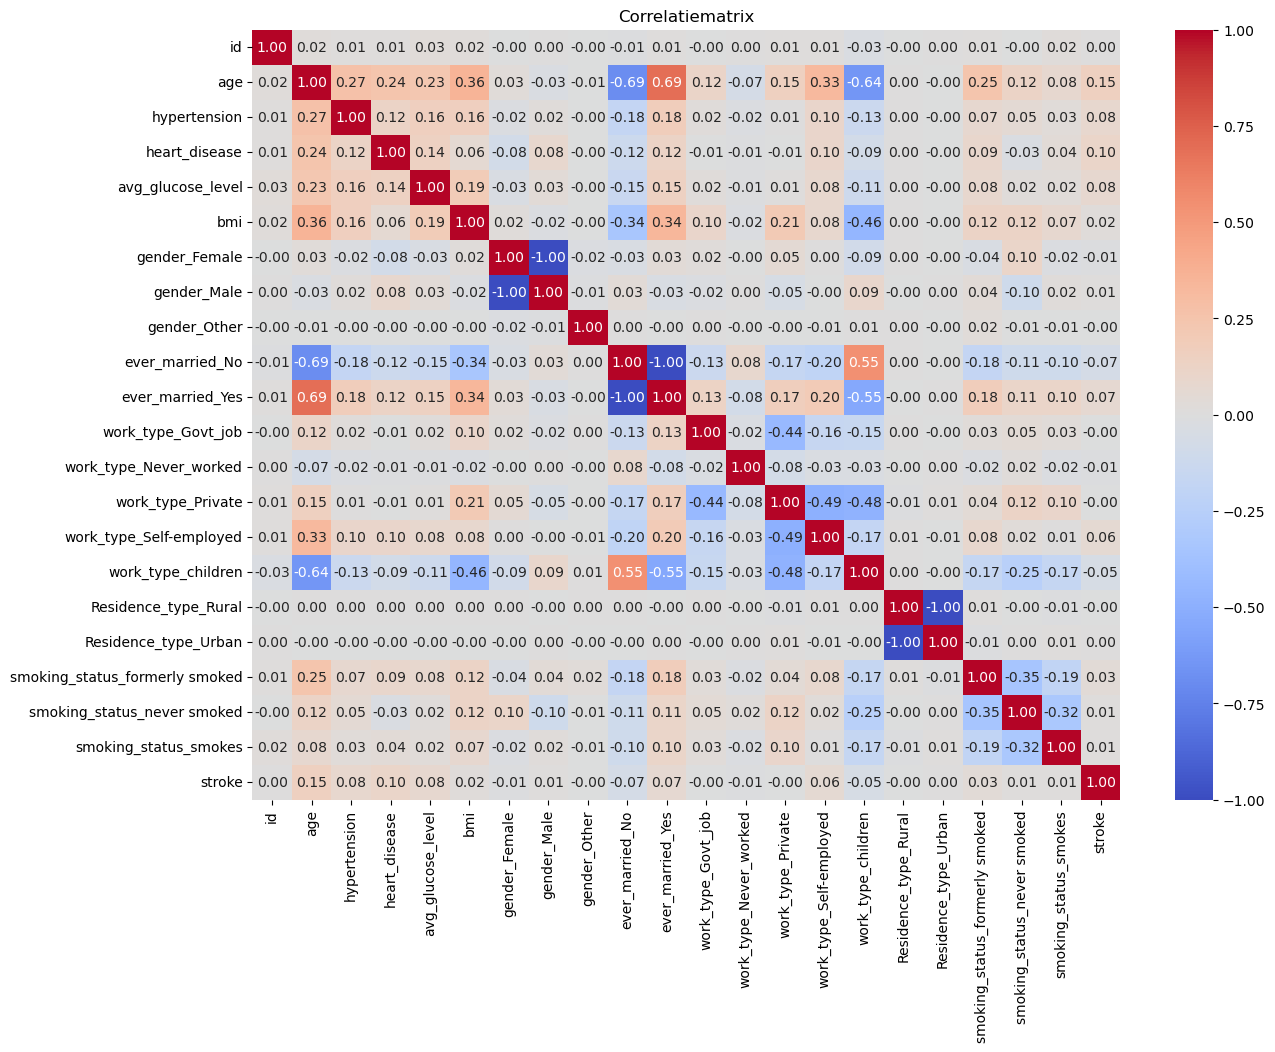

In [14]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    train.corr(),
    cmap='coolwarm',
    center=0,
    annot=True,
    fmt='.2f',
)

plt.title('Correlatiematrix')
plt.show()

## 1.8 Boxplots (Outliers)

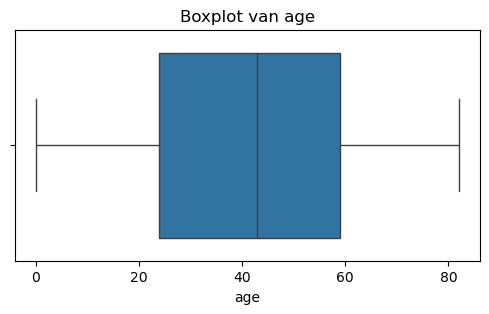

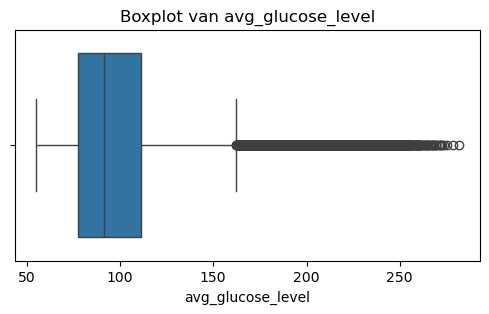

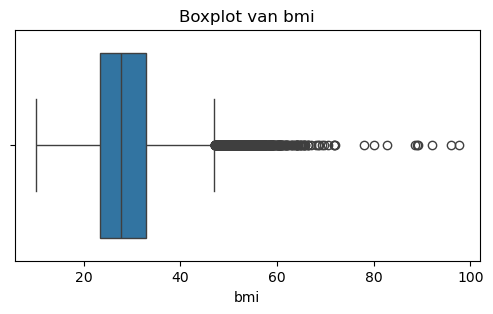

In [15]:
import seaborn as sns

for kol in numerieke_kolommen:
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=train[kol])
    plt.title(f'Boxplot van {kol}')
    plt.show()

## 1.9 Belangrijkste Bevindingen

#### <b>Imbalanced target</b>
We zien dat van de 33.550 patienten maar slechts 517 (1,54%) een stroke heeft gehad. Dit betekent dat de dataset sterk imbalanced is. Als ons model altijd "Geen Stroke" voorspelt zou het al ongeveer 98,5% accuracy behalen zonder daadwerkelijk iets te leren. Accuracy is daarom bij deze dataset geen geschikte metric om de prestaties van het model goed te beoordelen. Dit is ook de reden waarom in de opdracht de F1-score gebruikt wordt. Later in de opdracht moeten we daarom goed kijken hoe we met deze imbalance omgaan.

#### <b>Geen missende waardes</b>
Er zijn geen missende waardes aanwezig in de dataset. Hierdoor hoeven we geen extra stappen uit te voeren om ontbrekende data te verwijderen of in te vullen.

#### <b>Age, heart_disease, avg_glucose_level en hypertension zijn de meest gecorreleerde aan stroke</b>
Van de variabelen heeft age de sterkste correlatie met stroke, met een correlatie van ongeveer 0,15. Daarnaast zien we ook een correlatie tussen stroke met: heart_disease, avg_glucose_level en hypertension. Deze correlaties zijn echter nog steeds relatief zwak. Dit laat zien dat geen van deze afzonderlijke variabelen op zichzelf een sterke relatie hebben met stroke.

#### <b>BMI en categorische waarden hebben weinig voorspellende waarde</b>
We zien dat het BMI, gender, woonplaats, werktype en rookstatus allemaal zwakke correlaties met stroke laten zien. Op basis van onze verwachtingen hadden we vooral bij rookstatus een sterke correlatie verwacht. Dat de correlatie laag is betekent niet meteen dat roken geen invloed heeft op het risico van een stroke.

#### <b>Uitschieters</b>
Uit de boxplots blijkt dat BMI en avg_glucose_level relatief veel uitschieters bevatten. Dit zijn waarschijnlijk geen foutieve waardes maar realistische metingen.

## 1.10 Niet relevante kolommen

### 1.10.1 Identificerende kolom (ID)

De ID kolom is een administratief identificatie nummer zonder voorspellende waarde. De correlatie was ook al ~0,0007.
We bewaren alleen de test-ids voor de submission op kaggle, maar halen deze eruit zodat het model niet verward wordt met het trainen en testen.

In [16]:
tests_ids = test['id']

train = train.drop(columns=['id'])
test = test.drop(columns=['id'])

print("Nieuwe vorm train:", train.shape)
print("Nieuwe vorm test:", test.shape)

Nieuwe vorm train: (33550, 21)
Nieuwe vorm test: (8388, 20)


## 1.11 Standaardisatie van de data

Bij standaardisatie wordt voor iedere numerieke variabele het gemiddelde afgetrokken en wordt het resultaat gedeeld door de standaardafwijking: $z = \frac{x - \mu}{\sigma}$. De getransformeerde variabele heeft daardoor op de trainingsdata een gemiddelde van ongeveer 0 en een standaardafwijking van ongeveer 1. `StandardScaler` voert deze berekening per variabele uit. De methode is gevoelig voor uitschieters, omdat het gemiddelde en de standaardafwijking door extreme waarden worden beïnvloed ([scikit-learn developers, z.d.-a](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)).

### Waarom standaardiseren voor deze dataset?

De continue variabelen hebben duidelijk verschillende schalen. `age` loopt van 0,08 tot 82, `avg_glucose_level` van 55,01 tot 281,59 en `bmi` van 10,10 tot 97,60. Zonder standaardisatie kan een variabele met grotere numerieke verschillen zwaarder meetellen, ook als die inhoudelijk niet belangrijker is. Dit is vooral relevant voor K-Nearest Neighbors, omdat afstanden de voorspelling bepalen. De officiële scikit-learn-documentatie laat zien dat schalen bij KNN een andere neighbour structuur en beslisgrens kan opleveren. Schalen is ook relevant voor SVM en Logistic Regression; bij Logistic Regression convergeren de `sag`- en `saga`-solvers alleen betrouwbaar snel wanneer kenmerken ongeveer dezelfde schaal hebben ([scikit-learn developers, z.d.-b](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html); [scikit-learn developers, z.d.-c](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)).

### Gekozen werkwijze

We standaardiseren alleen de continue variabelen `age`, `avg_glucose_level` en `bmi` met `StandardScaler`. De binaire en one-hot-gecodeerde variabelen blijven 0 of 1. Voor KNN, Logistic Regression en SVM gebruiken we de onderstaande preprocessing in een `Pipeline`. Decision Tree, Random Forest, Gradient Boosted Decision Trees en XGBoost zijn boommodellen en worden vrijwel niet beïnvloed door schaling; voor deze modellen gebruiken we daarom de oorspronkelijke waarden ([scikit-learn developers, z.d.-b](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html)).

De scaler wordt hier alleen als herbruikbare pipeline gedefinieerd en nog niet op de volledige dataset gefit. Tijdens cross-validation moet `fit` uitsluitend op de trainingsfold worden uitgevoerd. Een pipeline zorgt ervoor dat het gemiddelde en de standaardafwijking per trainingsfold worden geleerd en voorkomt dat informatie uit de validatie- of testdata lekt ([scikit-learn developers, z.d.-d](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)).

Omdat de boxplots uitschieters tonen, vergelijken we later tijdens cross-validation `StandardScaler` eventueel met `RobustScaler`. We kiezen `StandardScaler` als onderbouwde basisinstelling, maar bepalen op basis van validatieresultaten of een robuust alternatief werkelijk beter presteert.

In [ ]:
# Prompt [nummer invullen]: Standaardisatie van de stroke-dataset
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

numeric_cols = [
    'age',
    'avg_glucose_level',
    'bmi',
]

# Laat zien hoever de schalen van deze variabelen uit elkaar liggen
scale_summary = (
    train[numeric_cols]
    .agg(['min', 'max', 'mean', 'std'])
    .T
    .round(2)
)

display(scale_summary)


def make_scaled_pipeline(model):
    """
    Pipeline voor de modellen die gevoelig zijn voor schaal. (KNN, LR, SVM).
    """
    preprocessor = ColumnTransformer(
        transformers=[
            (
                'scale',
                StandardScaler(),
                numeric_cols,
            ),
        ],
        remainder='passthrough',
        verbose_feature_names_out=False,
    )

    return Pipeline(
        steps=[
            ('preprocessing', preprocessor),
            ('model', model),
        ]
    )

,min,max,mean,std
age,0.08,82.00,41.82,22.48
avg_glucose_level,55.01,281.59,103.59,42.13
bmi,10.10,97.60,28.60,7.78


De numerieke kenmerken hebben duidelijk verschillende schalen. Vooral avg_glucose_level heeft een grotere standaardafwijking dan bmi. Bij afstandsgebaseerde en schaalgevoelige modellen kan hierdoor één kenmerk onevenredig veel invloed krijgen. Daarom standaardiseren we age, avg_glucose_level en bmi voor KNN, Logistic Regression en SVM. De standaardisatie vindt binnen de modelpipeline plaats, zodat het gemiddelde en de standaardafwijking uitsluitend uit de betreffende trainingsdata worden berekend. De binaire kenmerken blijven ongewijzigd.

# 2. Evaluatie

In dit hoofdstuk bepalen we met passende classificatiemetrics hoe goed de modellen presteren.

## 2.1 Train- en validatiestrategie

*Nog uit te werken:* beschrijf de gekozen splitsing en gestratificeerde cross-validation. Leg uit hoe preprocessing, standaardisatie en technieken voor klasse-onbalans binnen iedere trainingsfold blijven om datalekken te voorkomen.

## 2.2 Evaluatiemetrics en confusion matrix

*Nog uit te werken:* toon voor een zelfgekozen basismodel minimaal de confusion matrix, accuracy, precision, recall en F1-score. Leg voor iedere metric uit hoe deze wordt berekend en wat de metric in deze medische context betekent.

## 2.3 Keuze voor de F1-score

*Nog uit te werken:* onderbouw waarom Kaggle de F1-score gebruikt bij deze sterk ongebalanceerde classificatietaak. Bespreek daarbij de balans tussen precision en recall en de gevolgen van false positives en false negatives.

# 3. Modelleren en uitleg modellen

Voor ieder model passen we cross-validation en hyperparametertuning toe. Met de beste hyperparameters maken we voorspellingen voor `test.csv` en uploaden we een eigen submission naar Kaggle. Per model vergelijken we minimaal twee passende technieken voor de ongebalanceerde target en leggen we de werking daarvan uit.

## 3.1 Algemene modelaanpak

*Nog uit te werken:* beschrijf de gedeelde preprocessing- en evaluatiepipeline, de gekozen cross-validation, de primaire metric, de zoekmethode voor hyperparameters en de twee of meer imbalance-technieken. Houd per model de beste parameters, lokale F1-score, confusion matrix en Kaggle-F1 bij.

## 3.2 K-Nearest Neighbors

*Nog uit te werken:* leg de werking uit met afstand, Euclidische afstand en Manhattan-afstand. Leg uit waarom standaardisatie belangrijk is, hoe regularisatie/modelcomplexiteit bij KNN kan worden beïnvloed en welke hyperparameters de beste F1-score geven.

## 3.3 Logistic Regression

*Nog uit te werken:* leg de werking en loss-functie met formule uit. Leg gradient descent uit met een eenvoudig rekenvoorbeeld en relevante formules. Behandel de toepasselijke regularisatievormen, hun effect en de relatie met overfitting. Bepaal de beste hyperparameters.

## 3.4 SVM

*Nog uit te werken:* beschrijf de werking met relevante formules en een rekenvoorbeeld op een klein deel van de dataset. Leg kernel en kernel trick, de loss-functie en regularisatie uit en bepaal de beste hyperparameters.

## 3.5 Decision Tree

*Nog uit te werken:* beschrijf de werking en de criteria voor splitsingen. Bepaal de beste hyperparameters. Leg pruning en de toegepaste vormen uit en verbind pruning aan underfitting en overfitting.

## 3.6 Ensembles

Beschrijf voor de drie verplichte ensembles de werking, tuning en prestaties. Vergelijk bagging met boosting en bespreek trainingstijd met de termen sequential en parallel.

### 3.6.1 Random Forest

*Nog uit te werken:* uitleg, bagging/bootstrap aggregation, parallelle training, cross-validation, imbalance-technieken, hyperparametertuning, beste parameters, lokale resultaten en Kaggle-resultaat.

### 3.6.2 Gradient Boosted Decision Trees

*Nog uit te werken:* uitleg, boosting, sequential training en trainingstijd, cross-validation, imbalance-technieken, hyperparametertuning, beste parameters, lokale resultaten en Kaggle-resultaat.

### 3.6.3 XGBoost

*Nog uit te werken:* uitleg, boosting, sequential training en trainingstijd, cross-validation, imbalance-technieken, hyperparametertuning, beste parameters, lokale resultaten en Kaggle-resultaat.

## 3.7 Zelf samengesteld ensemble

*Nog uit te werken:* combineer minimaal drie modellen. Leg uit hoe het ensemble werkt, welke vorm van voting is gekozen, waarom die keuze past en waarom juist deze modellen zijn gecombineerd. Pas cross-validation, imbalance-technieken en tuning toe en rapporteer het Kaggle-resultaat.

# 4. Conclusie en advies

## 4.1 Vergelijking van modellen en ensembles

*Nog uit te werken:* geef in één tabel voor ieder model en ensemble de beste hyperparameters, prestaties in het notebook en score op Kaggle.

## 4.2 Beste model

*Nog uit te werken:* benoem welk model het beste presteert, waarom en met welke parameters.

## 4.3 Overige overwegingen

*Nog uit te werken:* bespreek naast prestaties onder andere foutkosten, uitlegbaarheid, robuustheid, trainingstijd, bias, generaliseerbaarheid en inzetbaarheid in een medische context.

## 4.4 Advies aan artsen

*Nog uit te werken:* adviseer welk model artsen als beslisondersteuning zouden kunnen gebruiken en onderbouw dit advies. Benoem beperkingen en voorwaarden voor veilig gebruik.

# 5. Referentielijst en verantwoording generatieve AI

*Vanaf nu bijhouden:* neem alle gebruikte tekst-, figuur- en codebronnen op volgens APA. Verwijs bij gebruik van generatieve AI ook naar een niet-AI-bron die de inhoud ondersteunt. Vermeld bij AI-gebruik model, versie, datum, promptnummer, chattitel en gedeelde link. Zet promptverwijzingen zowel in de relevante markdown als in comments bij ondersteunde code.

[Chat1](https://chatgpt.com/s/cx_6ab275c06318819196246f230cb02837)

## Bronnen standaardisatie

scikit-learn developers. (z.d.-a). *StandardScaler*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html

scikit-learn developers. (z.d.-b). *Importance of feature scaling*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html

scikit-learn developers. (z.d.-c). *LogisticRegression*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

scikit-learn developers. (z.d.-d). *Common pitfalls and recommended practices*. Scikit-learn. Geraadpleegd op 22 september 2026, van https://scikit-learn.org/stable/common_pitfalls.html

OpenAI. (2026, 22 september). *ChatGPT, GPT-5. Prompt [nummer invullen]: Standaardisatie van de stroke-dataset*. [Voeg vóór inlevering de gedeelde chatlink toe en maak de gebruikersnaam zichtbaar.]